# 火灾及烟雾检测数据集探索

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import seaborn as sns
import cv2
from ultralytics import YOLO
import warnings
warnings.filterwarnings('ignore')
# 关闭此 notebook 的 weights & biases (wandb) 报告功能
os.environ["WANDB_DISABLED"] = 'true'

In [6]:
# 设置路径
images_dir = 'archive/train/images'
labels_dir = 'archive/train/labels'

def load_images_and_labels(images_dir, labels_dir):
    """
    加载图片和对应的 YOLOv8 格式的标注文件

    参数：
    images_dir (str): 包含图片的目录路径 
    labels_dir (str): 包含 YOLOv8 标注文件的目录路径
    
    返回：
    tuple: 一个包含图片路径列表和字典的元祖，字典的键是图片路径、值是标注信息列表
    """
    images = []
    labels = {}

    # 遍历 images 目录中的所有文件
    for filename in os.listdir(images_dir):
        if filename.endswith('.jpg'): # 检查文件是否为 .jpg 文件
            image_path = os.path.join(images_dir, filename)
            label_filename = os.path.splitext(filename)[0] + '.txt'
            label_path = os.path.join(labels_dir, label_filename)

            if os.path.exists(label_path): # 检查标注文件是否存在
                images.append(image_path) # 将图片路径添加到列表
                with open(label_path, 'r') as f:
                    # 读取标注文件内容并将其存储在字典中
                    labels[image_path] = [line.strip().split() for line in f.readlines()]

    return images, labels

In [7]:
# 加载图片和标签
images, labels = load_images_and_labels(images_dir, labels_dir)

images[0]

'archive/train/images/Img_213_jpg.rf.7baf0925dafe69e43c4d39fff841c52f.jpg'

In [8]:
image = cv2.imread(images[0]) # 读取图片
image.shape # 查看图片形状

(640, 640, 3)

In [9]:
labels[images[0]]

[['0', '0.44375', '0.65859375', '0.153125', '0.2109375'],
 ['0', '0.2078125', '0.7171875', '0.06875', '0.059375'],
 ['0', '0.571875', '0.71328125', '0.04375', '0.1203125']]

In [12]:
def draw_bounding_boxes(image_path, annotations, class_names = None):
    """
    在图片上绘制边界框及其标签 ID

    参数：
    image_path (str) : 图片路径
    annotations (list): 标注信息列表，每个元素是一个包含类别 ID、中心坐标、宽度和高度的列表
    class_names (dict, optional)：类别 ID 到类名的映射字典

    返回：
    numpy.ndarray: 绘制了边界框的图片数组
    """
    image = cv2.imread(image_path) # 读取图片
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB) # 将颜色空间从 BGR 转换为 RGB

    h, w, _ = image.shape # 获取图片的高度和宽度

    for annotation in annotations:
        class_id = int(annotation[0]) # 获取类别 ID
        x_center, y_center, width, height = map(float, annotation[1:]) # 获取中心坐标、宽度和高度

        # 计算边界框的左上角和右下角的坐标
        x_min = int((x_center - width / 2) * w)
        y_min = int((y_center - height / 2) * h)
        x_max = int((x_center + width / 2) * w)
        y_max = int((y_center + height / 2) * h)

        # 随机生成边界框的颜色
        color = (random.randint(0, 255), random.randint(0, 255), random.randint(0, 255))
        cv2.rectangle(image, (x_min, y_min), (x_max, y_max), color, 2) # 绘制边界框

        # 如果提供了类别名称，则使用类别名称；否则使用类别 ID
        if class_names:
            label = f"{class_names[class_id]}: {class_id}"
        else:
            label = str(class_id)

        # 计算字体大小和粗细
        font_scale = min(w, h) / 600
        thickness = max(1, int(font_scale * 2))
        text_size, _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, font_scale, thickness)
        text_width, text_height = text_size

        # 绘制标签背景矩形
        cv2.rectangle(image, (x_min, y_min - text_height - 4), (x_min + text_width + 4, y_min), color, -1)
        # 在边界框上方绘制标签文本
        cv2.putText(image, label, (x_min + 2, y_min - 2), cv2.FONT_HERSHEY_SIMPLEX, font_scale, (255, 255, 255), thickness)

    return image



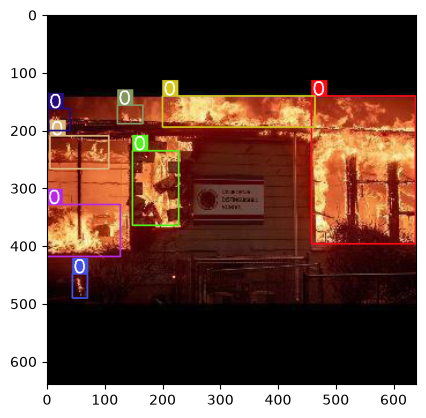

In [13]:
plt.imshow(draw_bounding_boxes(images[1], labels[images[1]]))

In [14]:
def display_images_with_annotations(images, labels, num_images = 9, class_names = None):
    """
    随机选择一定数量的图片并在每张图上绘制边界框及其标注 ID，然后显示这些图片

    参数：
    images (list): 图片路径列表
    labels (dict): 标签信息字典，键是图片路径，值是标注信息列表
    num_images (int, optional): 要显示的图片数量，默认为 9
    class_names (dict, optional): 类别 ID 到类名的映射字典
    """
    selected_images = random.sample(images, num_images) # 随机选择 num_images 张图片
    fig, axes = plt.subplots(nrows = (num_images // 3) + (1 if num_images % 3 != 0 else 0), ncols = 3, figsize = (15, 10))
    axes = axes.flatten()

    for ax, image_path in zip(axes, selected_images):
        annoteted_image = draw_bounding_boxes(image_path, labels[image_path], class_names) # 绘制边界框
        ax.imshow(annoteted_image) # 显示图片
        ax.axis('off') # 关闭坐标轴

    plt.tight_layout() # 自动调整子图参数，使之填充整个图片区域
    plt.show() # 显示所有图片

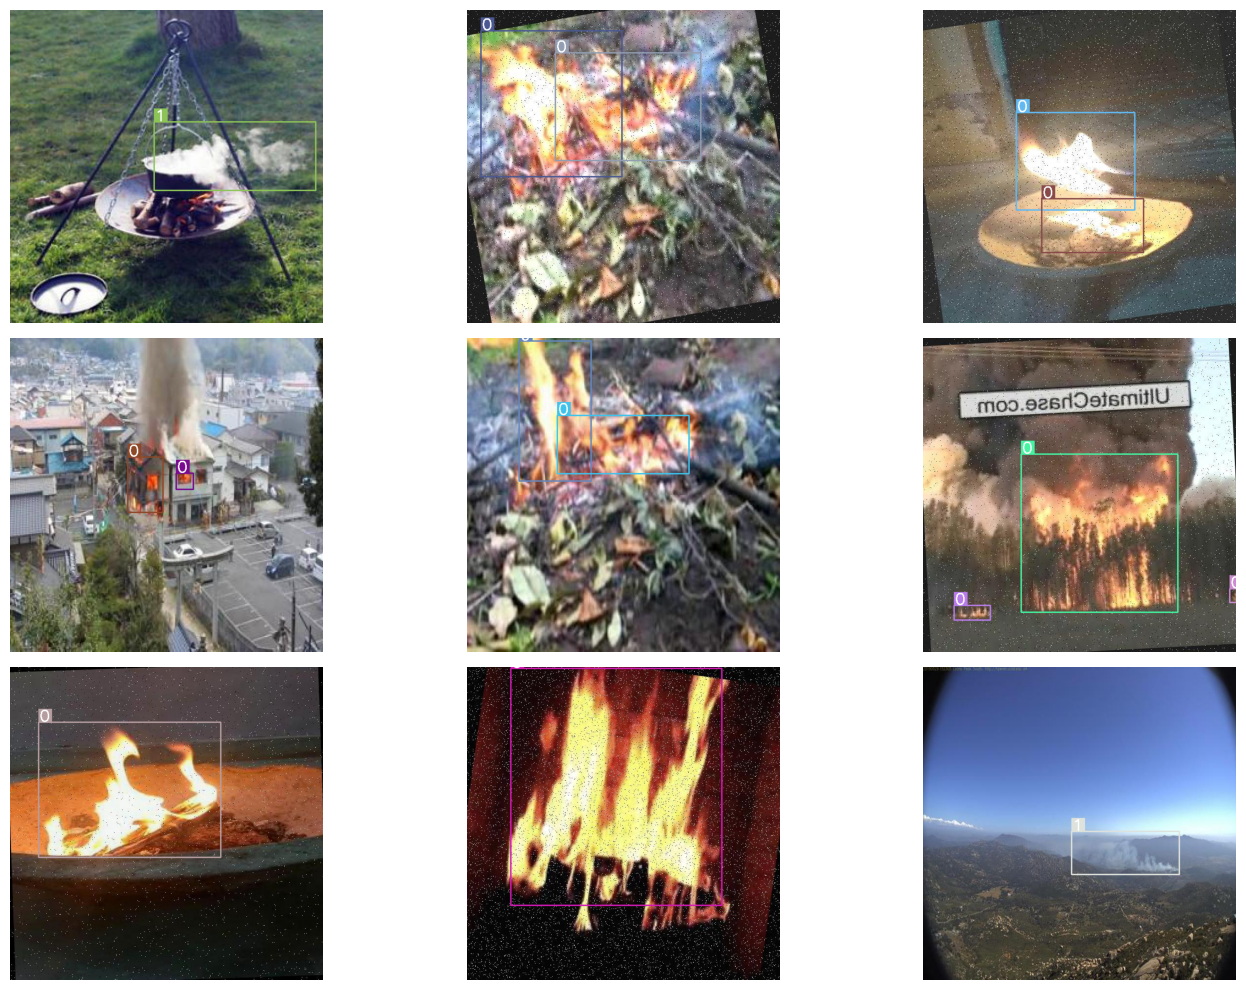

In [15]:
# 显示带边界框的图片
display_images_with_annotations(images, labels)